In [96]:
import numpy as np
import pandas as pd
from numpy import linalg
import math
import matplotlib.pyplot as plt


In [97]:
a = 2
b = 3


X = np.linspace(0, 10, 100)

y_0 = a * X + b


In [98]:
uglify = np.random.uniform(-1,1,size = 100)
uglify

array([ 6.19066764e-01,  1.63773431e-01, -3.01390128e-02, -3.60389512e-01,
        6.12095857e-02,  4.27818566e-01, -4.54989622e-01,  5.88680426e-01,
        2.00241006e-01,  5.26908175e-01,  6.14389167e-01, -8.25687480e-01,
        6.56975777e-01,  1.49072628e-01,  4.35400339e-01, -3.52604395e-01,
       -2.98131637e-01, -8.21559918e-01,  8.26419370e-01,  3.09101731e-01,
        6.51940821e-01, -2.27139464e-02, -6.94159720e-01,  9.73411764e-01,
       -9.81849545e-01, -2.63388259e-02,  3.00186393e-01,  5.43045907e-01,
       -5.98311741e-01, -4.05717474e-01, -1.52761497e-01,  6.75476606e-01,
        1.60559970e-01,  1.03211218e-01, -6.97707717e-01, -5.71924955e-01,
        7.30602431e-01,  6.29163303e-01, -4.92231504e-01,  2.49318358e-01,
       -1.79815439e-01, -3.01250572e-01,  3.58802412e-01,  6.39926353e-01,
        7.90229521e-01, -4.13152552e-01,  5.39601461e-01, -8.48273381e-01,
        6.23986989e-01, -9.20439978e-04,  6.44108375e-01, -2.91726464e-01,
        7.16860542e-01, -

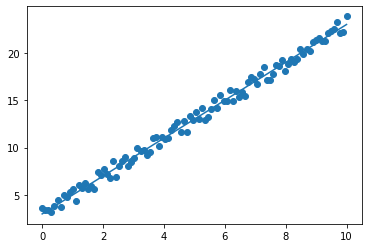

In [99]:
y = y_0 + uglify
plt.plot(X,y_0)
#plt.show()
plt.scatter(X, y)
plt.show()

In [100]:
A = np.array([[sum(X*X),sum(X)],
              [sum(X),len(X)]])
b = [sum(X*y),sum(y)]

In [101]:
#SSE = sum(y-y_pred)**2
#SST = sum(y-y_mean)**2

SSE = sum((y-y_n)**2)
SST = sum((y-np.mean(y))**2)

r_squared = 1 - (SSE/SST)
print(r_squared)

0.9908737612009315


[1.99044372 3.09472442]


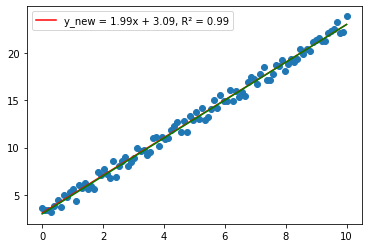

In [102]:
coeff = linalg.solve(A,b)
y_n = coeff[0]*X + coeff[1]
plt.plot(X,y_n,color = 'r', label = "y_new = {:.2f}x + {:.2f}, R² = {:.2f}".format(coeff[0],coeff[1], r_squared))
plt.scatter(X, y)
plt.legend()
plt.plot(X,y_0,color = 'g')
print(coeff)

In [103]:
from sklearn.linear_model import LinearRegression

In [104]:
model = LinearRegression()
model.fit(X.reshape(-1, 1), y)

y_pred = model.predict(X.reshape(-1, 1))
y_pred

array([ 3.09472442,  3.29577934,  3.49683426,  3.69788918,  3.8989441 ,
        4.09999902,  4.30105394,  4.50210886,  4.70316379,  4.90421871,
        5.10527363,  5.30632855,  5.50738347,  5.70843839,  5.90949331,
        6.11054823,  6.31160315,  6.51265808,  6.713713  ,  6.91476792,
        7.11582284,  7.31687776,  7.51793268,  7.7189876 ,  7.92004252,
        8.12109744,  8.32215236,  8.52320729,  8.72426221,  8.92531713,
        9.12637205,  9.32742697,  9.52848189,  9.72953681,  9.93059173,
       10.13164665, 10.33270157, 10.5337565 , 10.73481142, 10.93586634,
       11.13692126, 11.33797618, 11.5390311 , 11.74008602, 11.94114094,
       12.14219586, 12.34325079, 12.54430571, 12.74536063, 12.94641555,
       13.14747047, 13.34852539, 13.54958031, 13.75063523, 13.95169015,
       14.15274507, 14.3538    , 14.55485492, 14.75590984, 14.95696476,
       15.15801968, 15.3590746 , 15.56012952, 15.76118444, 15.96223936,
       16.16329429, 16.36434921, 16.56540413, 16.76645905, 16.96

In [105]:
a_1, b_1 =model.coef_, model.intercept_

y_lib = a_1*X + b_1

SSE_lib = sum((y-y_lib)**2)
SST_lib = sum((y-np.mean(y))**2)

r_squared_lib = 1 - (SSE_lib/SST_lib)
print("r_squared = ", r_squared)
print("r_squared_lib = ", r_squared_lib)
print("Difference: ", r_squared_lib - r_squared)

r_squared =  0.9908737612009315
r_squared_lib =  0.9918880626681857
Difference:  0.0010143014672542305


In [108]:
slope, intercept = np.polyfit(X, y, 1)

y_np = slope*X + intercept

In [109]:
r_squared_np = 1 - (sum((y-y_np)**2)/sum((y-np.mean(y))**2))
print("r_squared = ", r_squared)
print("r_squared_lib = ", r_squared_lib)
print("r_squared_np = ", r_squared_np)

r_squared =  0.9908737612009315
r_squared_lib =  0.9918880626681857
r_squared_np =  0.9918880626681859


In [111]:
print("coefficients of the linear regression model: ", coeff[0],coeff[1])
print("coefficients of the linear regression model using sklearn: ", float(a_1), b_1)
print("coefficients of the linear regression model using numpy: ", slope, intercept)

coefficients of the linear regression model:  1.9904437183305463 3.0947244173951947
coefficients of the linear regression model using sklearn:  1.9904437183305483 3.0947244173951862
coefficients of the linear regression model using numpy:  1.9904437183305488 3.0947244173951844


/var/folders/cg/9cz__yvn0qz5shgsxln7pmn00000gn/T/ipykernel_1420/3327386377.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("coefficients of the linear regression model using sklearn: ", float(a_1), b_1)


In [112]:
## კვადრატული ამოვხსნა და შევადარო სტანდარტულს